## Dataset overview and preprocessing

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'data/products.parquet').exists(): ROOT = ROOT.parent
assert (ROOT / 'data/products.parquet').exists(), 'Start in the repository or evaluation directory.'
sys.path.insert(0, str(ROOT))
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['TRANSFORMERS_OFFLINE'] = '1'
os.environ['HF_HOME'] = str(ROOT / '.cache/huggingface')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from backend.search import ProductSearch
from backend.unified_search import UnifiedSearch
from backend.query_understanding import understand_query
from unittest.mock import patch
import hashlib

products = pd.read_parquet(ROOT / 'data/products.parquet')
display(pd.DataFrame({'products': [len(products)], 'main categories': [products.main_category.nunique()]}))
print('E5: intfloat/multilingual-e5-small, revision 614241f622f53c4eeff9890bdc4f31cfecc418b3')

C:\Users\User\Projects\Relevia\.pixi\envs\default\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,products,main categories
0,1120,12


E5: intfloat/multilingual-e5-small, revision 614241f622f53c4eeff9890bdc4f31cfecc418b3


In [2]:
# Stable, product-ID-based sampling: two titles per category, independent of rankings.
products['sample_key'] = products.parent_asin.map(lambda x: hashlib.sha256(('text-v1:' + x).encode()).hexdigest())
queries = products.sort_values('sample_key').groupby('main_category', sort=True).head(2)
assert len(queries) == 24 and queries.parent_asin.is_unique
display(queries[['main_category', 'parent_asin', 'title']].reset_index(drop=True))

,main_category,parent_asin,title
0,Computers & Components,B071YVGZ79,ViewSonic VA2746MH-LED 27 Inch Full HD 1080p L...
1,Computers & Components,B0BL98PP21,"Acer KG241Q Pbiip 23.6"" Full HD (1920 x 1080) ..."
2,Headphones & Earbuds,B07H63LJ7S,"SilverStone Technology Headphone Mount, Charco..."
3,Headphones & Earbuds,B01H3EEOD4,Samsung Gear IconX 2016 Cordfree Fitness Earbu...
4,Security & Surveillance,B0953CV398,"LaView Security Cameras Wireless Outdoor,1080P..."
5,Data Storage,B0923PPP3C,"PNY Retract USB 2.0 Flash Drive, 32GB, Gray, B..."
6,Networking,B0C1J8RZ46,TP-Link TL-SG108 | 8 Port Gigabit Unmanaged Et...
7,Data Storage,B0B8T9RF31,SABRENT 4TB Rocket NVMe PCIe M.2 2280 Internal...
8,Networking,B09H2Y1M8K,"USB C Hub,UtechSmart 6 in 1 USB C to HDMI Adap..."
9,Power & Lighting,B0946MX5S2,"Multi Plug Outlet Extender, EyGde Outlet Split..."


## Model and index loading

In [3]:
# Never rebuild the production index during evaluation.
def no_rebuild(*args, **kwargs):
    raise RuntimeError('Text cache is missing or invalid; prepare it separately.')
with patch.object(ProductSearch, 'build_index', no_rebuild):
    search = ProductSearch()
assert search.cache_hit
hybrid = UnifiedSearch()
hybrid.text_search = search
print(f'Reused FAISS index: {search.index.ntotal} × {search.index.d}; E5 loads from local cache.')

Reused FAISS index: 1120 × 384; E5 loads from local cache.


## Fresh inference

In [4]:
rankings = []
for row in queries.itertuples():
    parsed = understand_query(row.title)
    # Apply the same explicit numeric constraints to all three systems.
    bm25 = search.keyword(parsed['text'], len(products))
    e5 = search.semantic(parsed['text'], len(products))
    def apply_filters(results):
        wrapped = [{'product': search.products[search.ids.index(r['parent_asin'])],
                    'score': r['score'], 'reasons': []} for r in results]
        return [r['product_id'] for r in UnifiedSearch.filter_results(
            wrapped, min_price=parsed['min_price'], max_price=parsed['max_price'],
            min_rating=parsed['min_rating'], limit=10)]
    for name, ids in [('BM25', apply_filters(bm25)), ('E5', apply_filters(e5)),
                      ('Hybrid', [r['product_id'] for r in hybrid.text(row.title, limit=10)])]:
        rank = ids.index(row.parent_asin) + 1 if row.parent_asin in ids else None
        rankings.append({'method': name, 'category': row.main_category, 'target': row.parent_asin, 'rank': rank})
rankings = pd.DataFrame(rankings)
display(rankings.head(9))


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


Loading weights:  72%|███████▏  | 144/199 [00:00<00:00, 450.00it/s]


Loading weights:  95%|█████████▌| 190/199 [00:00<00:00, 327.68it/s]


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 360.51it/s]

,method,category,target,rank
0,BM25,Computers & Components,B071YVGZ79,1
1,E5,Computers & Components,B071YVGZ79,1
2,Hybrid,Computers & Components,B071YVGZ79,1
3,BM25,Computers & Components,B0BL98PP21,1
4,E5,Computers & Components,B0BL98PP21,1
5,Hybrid,Computers & Components,B0BL98PP21,1
6,BM25,Headphones & Earbuds,B07H63LJ7S,1
7,E5,Headphones & Earbuds,B07H63LJ7S,1
8,Hybrid,Headphones & Earbuds,B07H63LJ7S,1


## Identity metrics and chart

,P@5,P@10,Recall@5,Recall@10,Hit@5,Hit@10,MRR@10,NDCG@10
method,,,,,,,,
BM25,0.2,0.1,1.0,1.0,1.0,1.0,1.0,1.0
E5,0.2,0.1,1.0,1.0,1.0,1.0,1.0,1.0
Hybrid,0.2,0.1,1.0,1.0,1.0,1.0,1.0,1.0


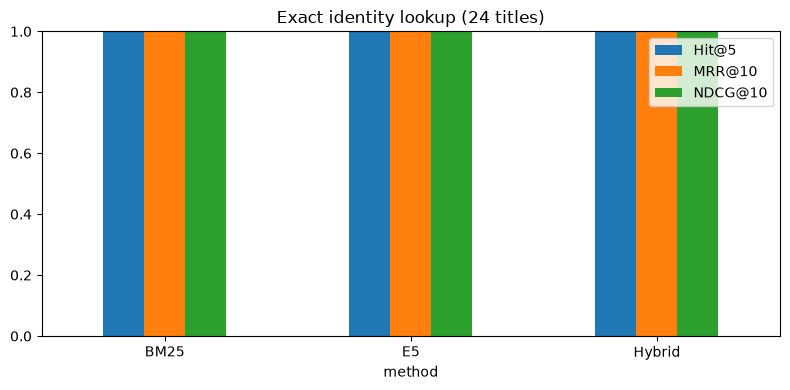

In [5]:
def identity_metrics(group):
    rank = group['rank'].fillna(np.inf)
    hit5, hit10 = (rank <= 5).mean(), (rank <= 10).mean()
    return pd.Series({'P@5': hit5/5, 'P@10': hit10/10, 'Recall@5': hit5,
                      'Recall@10': hit10, 'Hit@5': hit5, 'Hit@10': hit10,
                      'MRR@10': (1/rank).mean(), 'NDCG@10': (1/np.log2(rank+1)).mean()})
metrics = rankings.groupby('method').apply(identity_metrics, include_groups=False).reindex(['BM25', 'E5', 'Hybrid'])
display(metrics.round(3))
metrics[['Hit@5', 'MRR@10', 'NDCG@10']].plot.bar(rot=0, ylim=(0,1), figsize=(8,4), title='Exact identity lookup (24 titles)')
plt.tight_layout(); plt.show()

## Interpretation

One identity target per query: Recall@K = Hit@K and Precision@K = Hit@K/K. MRR and NDCG are truncated at 10; relevance evaluation requires independent judgments.